In [1]:
!pip install catboost

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

/usr/local/lib/python3.13/dist-packages/sklearn/experimental/enable_hist_gradient_boosting.py:19: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [3]:
df = pd.read_csv("Ames Housing Dataset.csv")

In [4]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
df.shape

(1460, 81)

In [6]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [8]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [9]:
df["SalePrice"].describe()

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df = df.drop_duplicates()

In [12]:
df = df.drop(columns="Id")

In [13]:
df.isnull().sum().sort_values(ascending=False).head(20)

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageQual,81
GarageType,81
GarageFinish,81


In [14]:
text_cols = df.select_dtypes(exclude="number").columns
df[text_cols] = df[text_cols].fillna("None")

In [15]:
df["LotFrontage"] = df["LotFrontage"].fillna(df["LotFrontage"].median())
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(df["YearBuilt"])
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)

In [16]:
df.isnull().sum().sum()

np.int64(0)

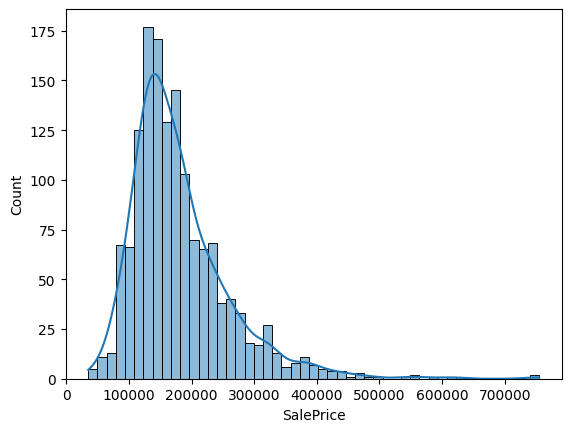

In [17]:
sns.histplot(df["SalePrice"], kde=True)
plt.show()

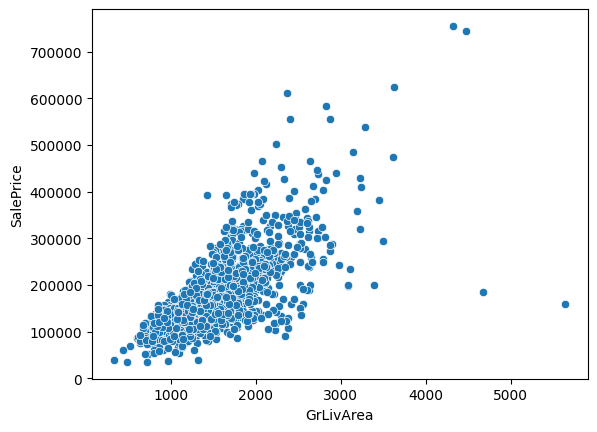

In [18]:
sns.scatterplot(x="GrLivArea", y="SalePrice", data=df)
plt.show()

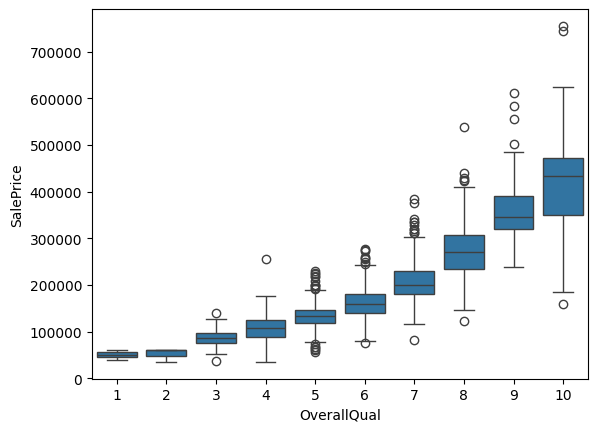

In [19]:
sns.boxplot(x="OverallQual", y="SalePrice", data=df)
plt.show()

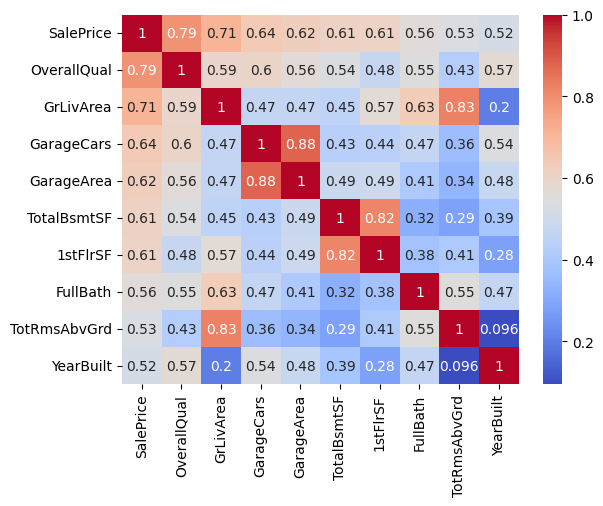

In [20]:
top_cols = df.corr(numeric_only=True)["SalePrice"].abs().sort_values(ascending=False).head(10).index
sns.heatmap(df[top_cols].corr(), annot=True, cmap="coolwarm")
plt.show()

In [21]:
df = df[df["GrLivArea"] < 4000]

In [22]:
df_clean = df.copy()

In [23]:
quality = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
quality_cols = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
                "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
for col in quality_cols:
    df[col] = df[col].map(quality)

In [24]:
df["CentralAir"] = df["CentralAir"].map({"N": 0, "Y": 1})

In [25]:
df["MSSubClass"] = df["MSSubClass"].astype(str)

In [26]:
high_card = ["Neighborhood", "Exterior1st", "Exterior2nd"]

In [27]:
onehot_cols = [c for c in df.select_dtypes(exclude="number").columns if c not in high_card]
df = pd.get_dummies(df, columns=onehot_cols, drop_first=True, dtype=int)

In [28]:
X = df.drop(columns="SalePrice")

In [29]:
y = np.log1p(df["SalePrice"])

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [31]:
target_means = {}
for col in high_card:
    target_means[col] = y_train.groupby(X_train[col]).mean()
    X_train[col] = X_train[col].map(target_means[col])
    X_test[col] = X_test[col].map(target_means[col]).fillna(y_train.mean())

In [32]:
num_cols = [c for c in X_train.columns if X_train[c].nunique() > 2]

In [33]:
skewed = [c for c in num_cols if abs(X_train[c].skew()) > 0.75]
X_train[skewed] = np.log1p(X_train[skewed])
X_test[skewed] = np.log1p(X_test[skewed])

In [34]:
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [35]:
y_real = np.expm1(y_test)

In [36]:
models = {
    "Linear Regression": LinearRegression(),
    "KNN": GridSearchCV(KNeighborsRegressor(),
                        {'n_neighbors': [3, 5, 7, 9, 11], 'weights': ['uniform', 'distance']},
                        cv=5, scoring='r2'),
    "SVR": GridSearchCV(SVR(), {'C': [0.01, 0.1, 1], 'kernel': ['linear', 'rbf']},
                        cv=5, scoring='r2'),
    "Decision Tree": GridSearchCV(DecisionTreeRegressor(criterion="squared_error", random_state=100),
                                  {'max_depth': [5, 10, 15], 'min_samples_leaf': [1, 5, 10]},
                                  cv=5, scoring='r2'),
}

In [37]:
results = []

In [38]:
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = np.expm1(model.predict(X_test))

    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_real, y_pred),
        'MSE': mean_squared_error(y_real, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_real, y_pred)),
        'R2': r2_score(y_real, y_pred)
    })

for name, model in models.items():
    if hasattr(model, "best_params_"):
        print("Best Parameters", name, ":", model.best_params_)

results_df = pd.DataFrame(results).set_index('Model').sort_values('R2', ascending=False)
results_df.round(3)

Best Parameters KNN : {'n_neighbors': 9, 'weights': 'distance'}
Best Parameters SVR : {'C': 0.01, 'kernel': 'linear'}
Best Parameters Decision Tree : {'max_depth': 15, 'min_samples_leaf': 10}


,MAE,MSE,RMSE,R2
Model,,,,
SVR,13732.219,3.806011e+08,19509.000,0.927
Linear Regression,14207.955,4.203866e+08,20503.332,0.920
KNN,20499.064,9.599378e+08,30982.863,0.817
Decision Tree,22486.342,1.182343e+09,34385.211,0.775


In [39]:
best_model = models[results_df.index[0]]
print("Best Model:", results_df.index[0])

Best Model: SVR


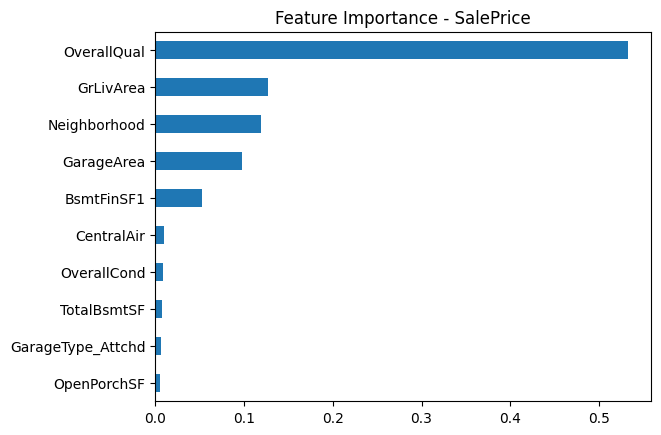

In [40]:
imp = pd.Series(models["Decision Tree"].best_estimator_.feature_importances_, index=X_train.columns)
imp.sort_values(ascending=False).head(10).sort_values().plot(kind="barh", title="Feature Importance - SalePrice")
plt.show()

In [41]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [42]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

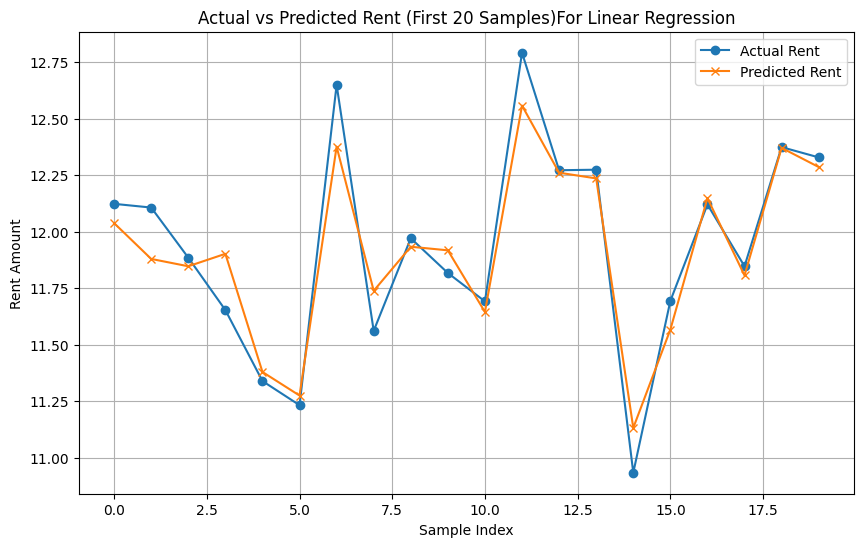

  7%|▋         | 1/15 [00:00<00:04,  3.19it/s]

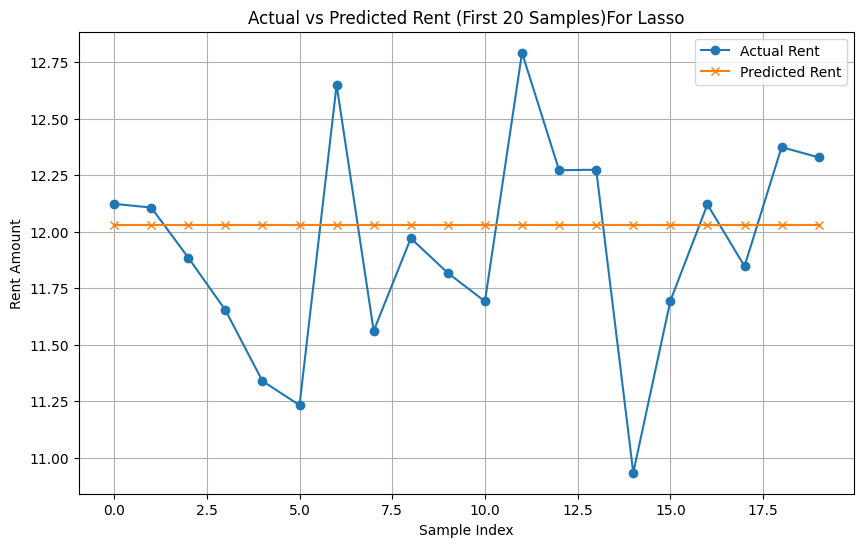

 13%|█▎        | 2/15 [00:00<00:03,  3.66it/s]

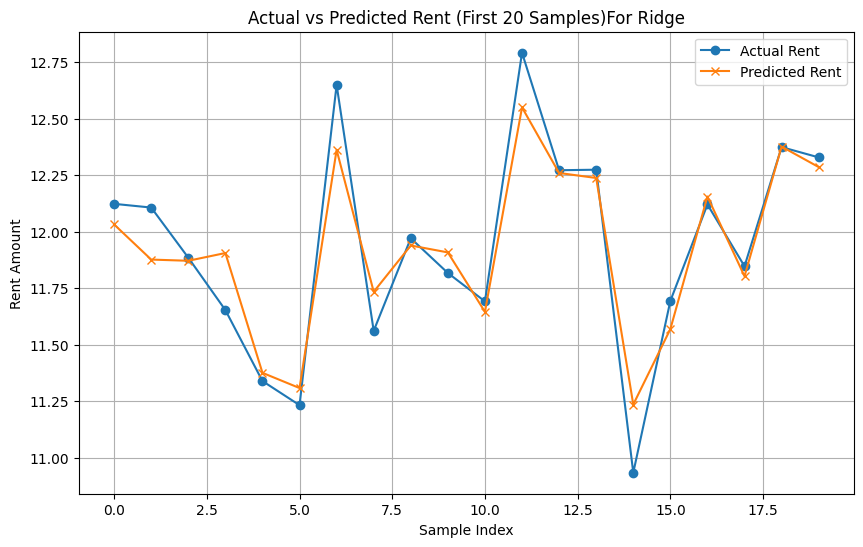

 20%|██        | 3/15 [00:00<00:03,  3.47it/s]

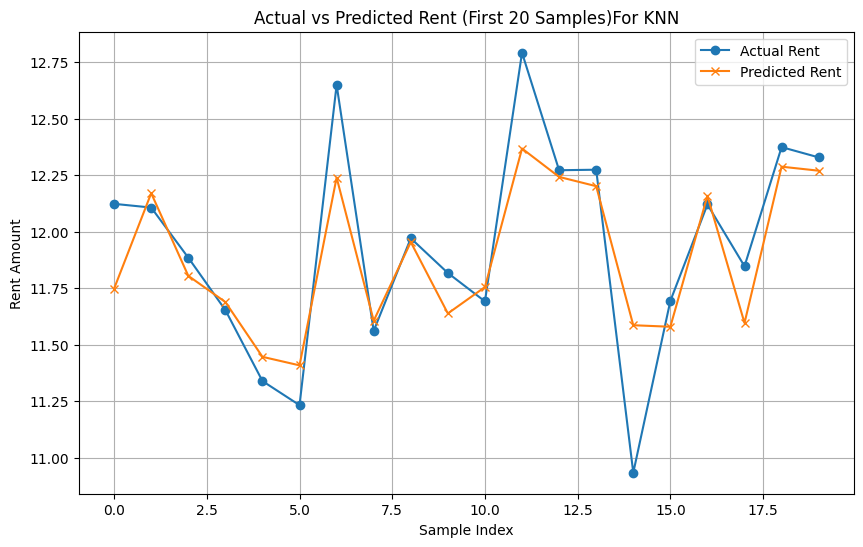

 27%|██▋       | 4/15 [00:01<00:05,  2.16it/s]

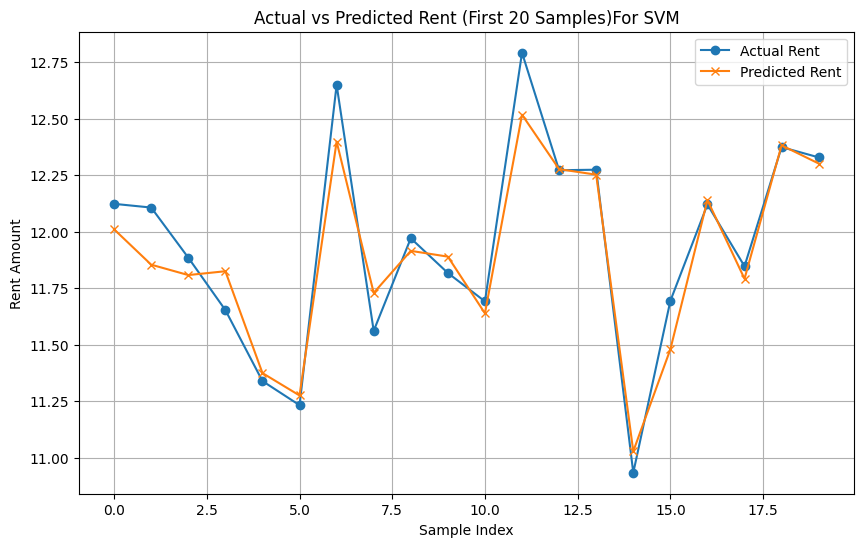

 33%|███▎      | 5/15 [05:36<20:11, 121.16s/it]

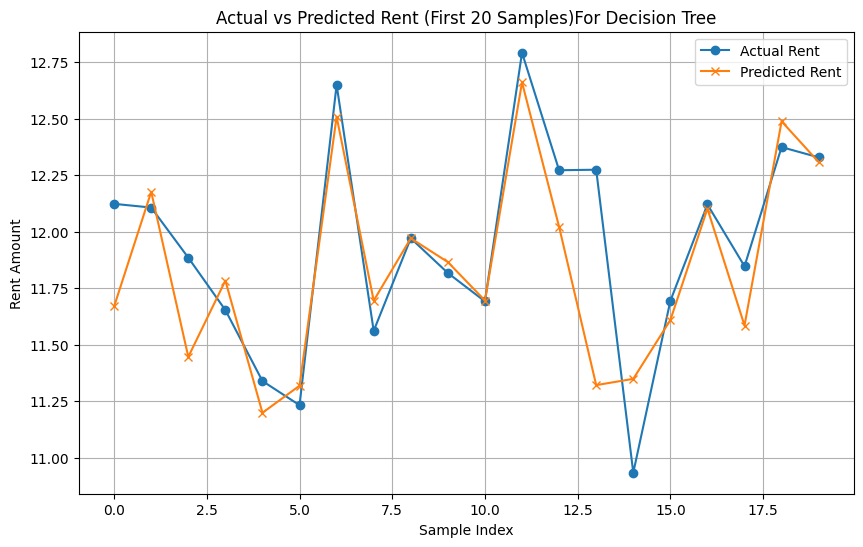

 40%|████      | 6/15 [05:37<12:00, 80.10s/it] 

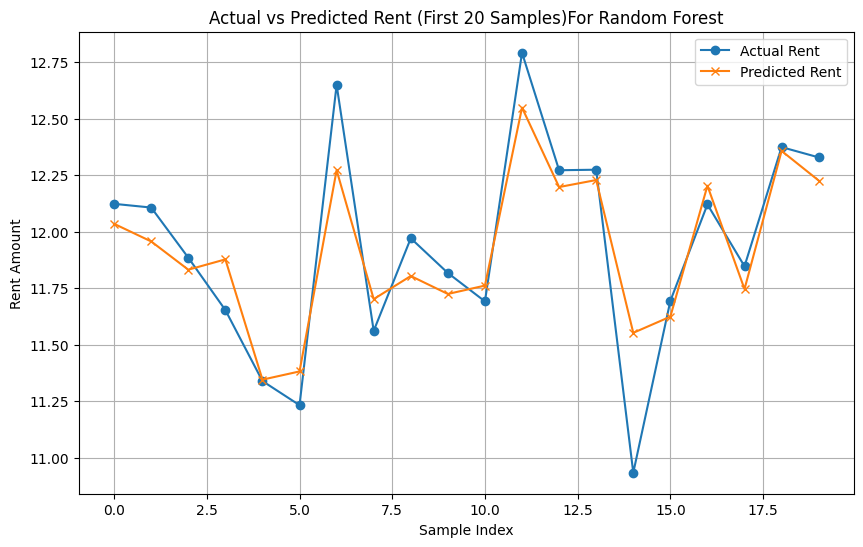

 47%|████▋     | 7/15 [05:39<07:16, 54.61s/it]

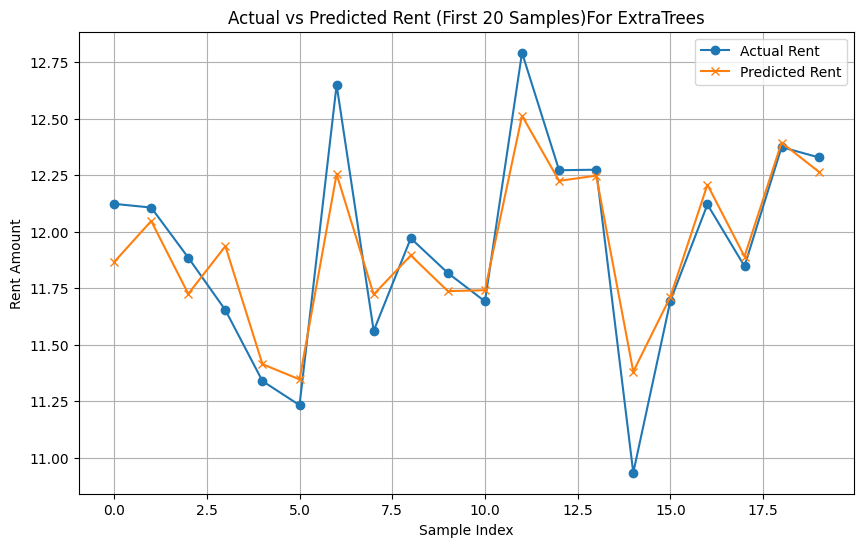

 53%|█████▎    | 8/15 [05:42<04:27, 38.24s/it]

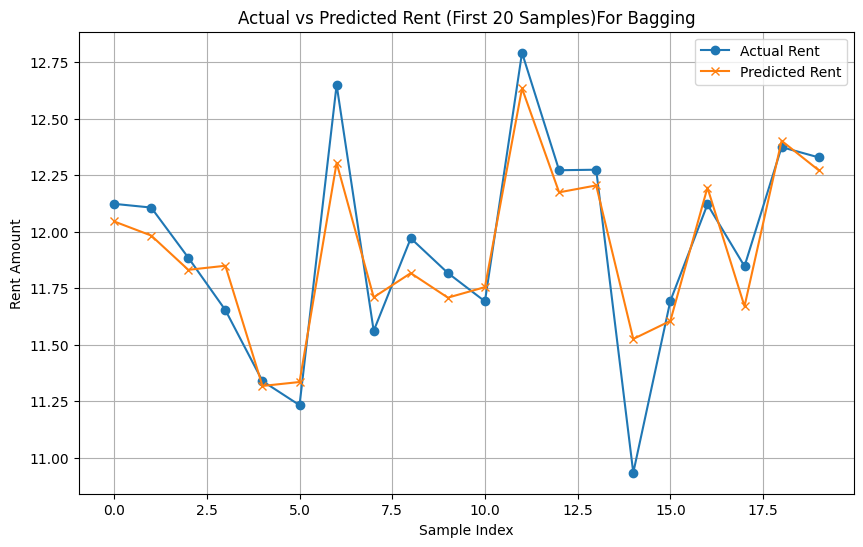

 60%|██████    | 9/15 [05:44<02:40, 26.79s/it]

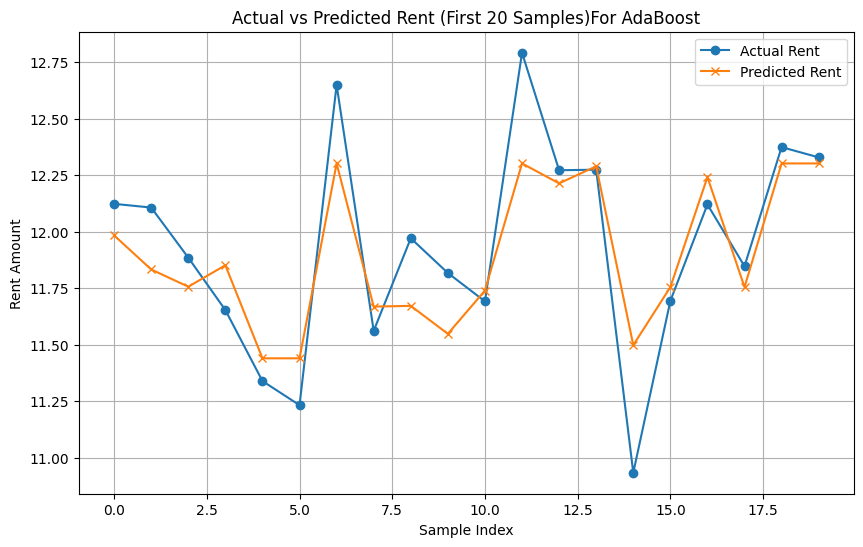

 67%|██████▋   | 10/15 [05:44<01:33, 18.67s/it]

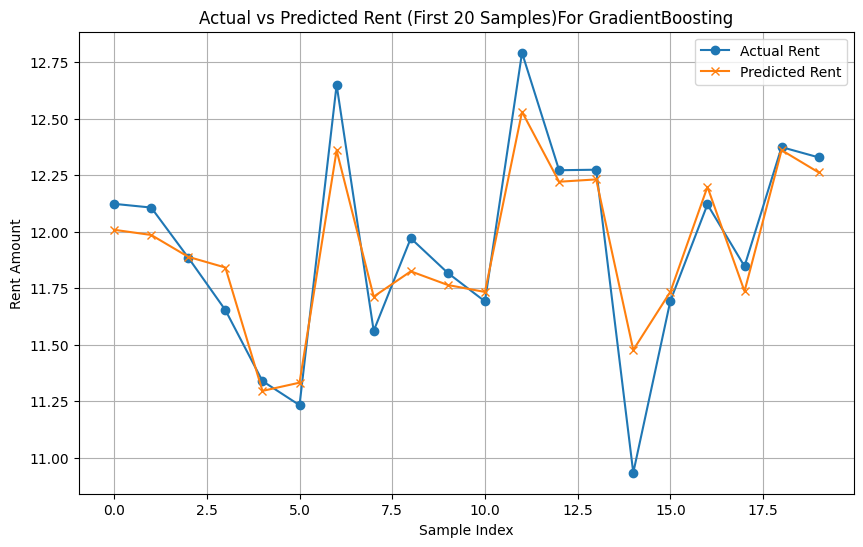

 73%|███████▎  | 11/15 [05:46<00:53, 13.43s/it]

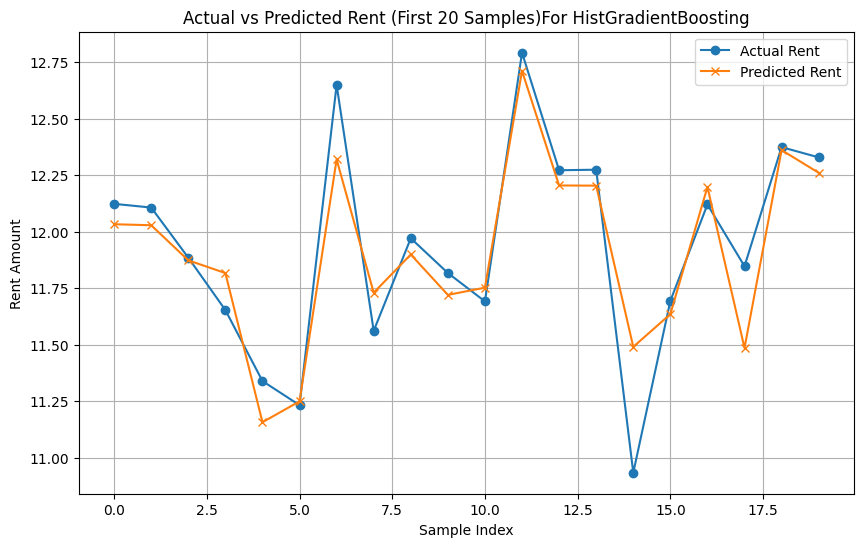

 80%|████████  | 12/15 [05:47<00:29,  9.85s/it]

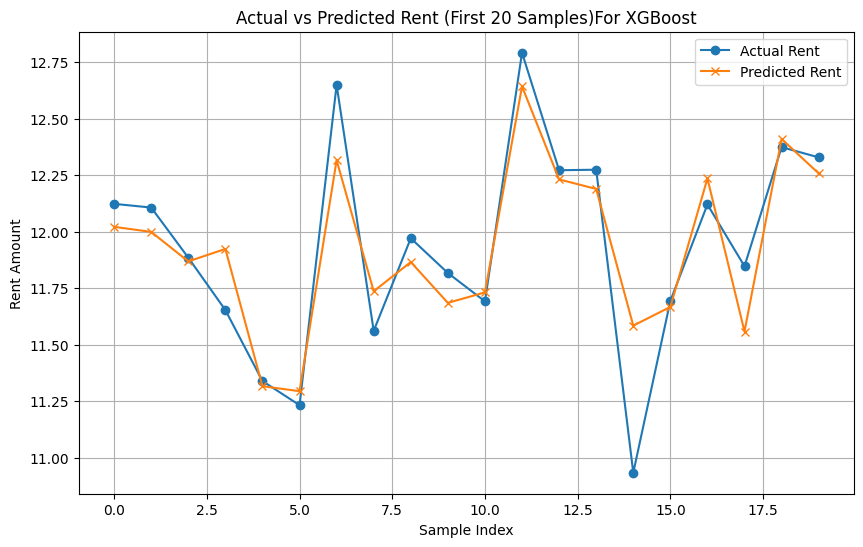

 87%|████████▋ | 13/15 [05:48<00:14,  7.14s/it]

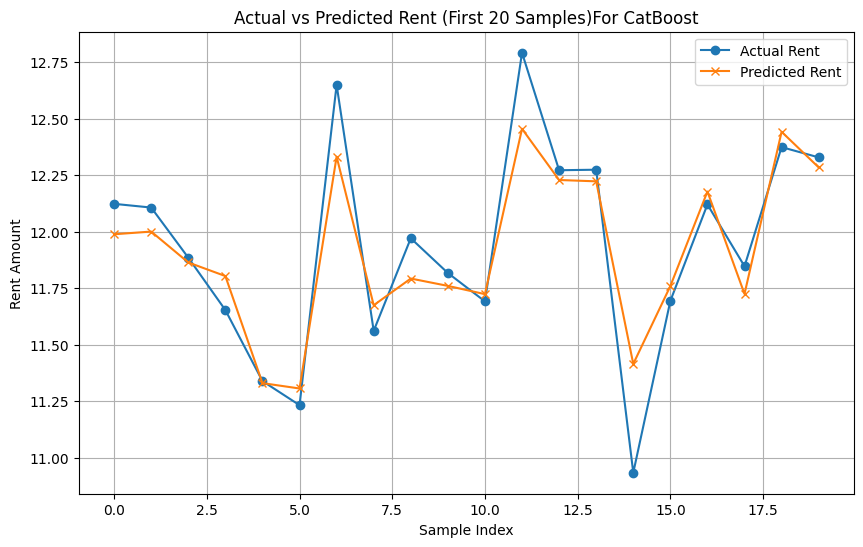

 93%|█████████▎| 14/15 [05:50<00:05,  5.50s/it]

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001430 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3164
[LightGBM] [Info] Number of data points in the train set: 1164, number of used features: 127
[LightGBM] [Info] Start training from score 12.028422


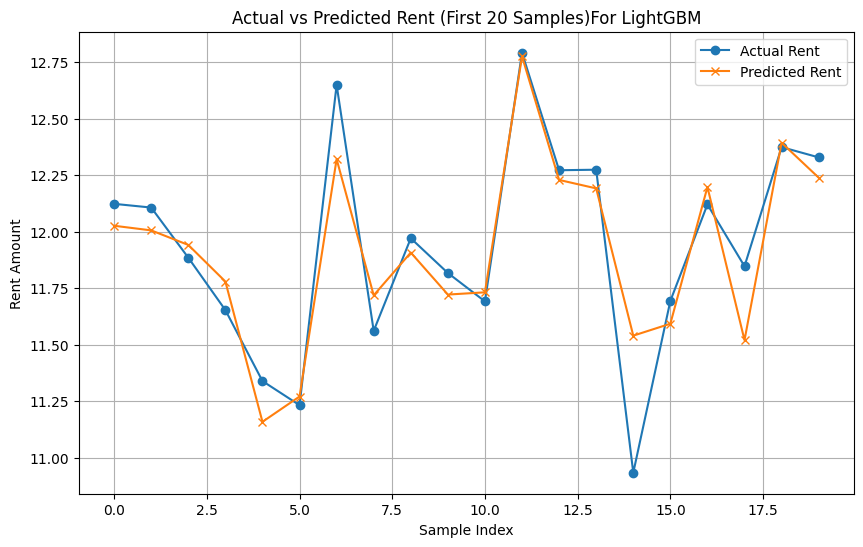

100%|██████████| 15/15 [05:51<00:00, 23.41s/it]


In [43]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [44]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [45]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [46]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [47]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
CatBoost,6.164194e-02,0.081694,6.935517e-03,0.014069,8.327975e-02,0.118614,0.955618,0.910920
Ridge,6.844292e-02,0.083747,9.048486e-03,0.014280,9.512353e-02,0.119499,0.942096,0.909585
Linear Regression,6.716613e-02,0.085024,8.786831e-03,0.014427,9.373810e-02,0.120113,0.943771,0.908653
SVM,7.300824e-02,0.088512,9.631684e-03,0.015329,9.814114e-02,0.123811,0.938364,0.902943
GradientBoosting,5.586281e-02,0.087824,5.559063e-03,0.016053,7.455912e-02,0.126699,0.964426,0.898361
HistGradientBoosting,2.422758e-02,0.087914,1.449903e-03,0.016391,3.807759e-02,0.128028,0.990722,0.896217
LightGBM,2.417004e-02,0.088447,1.438188e-03,0.017251,3.792344e-02,0.131345,0.990797,0.890772
ExtraTrees,1.082448e-14,0.092015,1.755744e-28,0.018353,1.325045e-14,0.135473,1.000000,0.883798
Voting,3.081201e-02,0.088447,1.948028e-03,0.017251,4.413647e-02,0.131345,0.987534,0.883461
Simple Voting,3.081201e-02,0.088447,1.948028e-03,0.017251,4.413647e-02,0.131345,0.987534,0.883461


<Axes: >

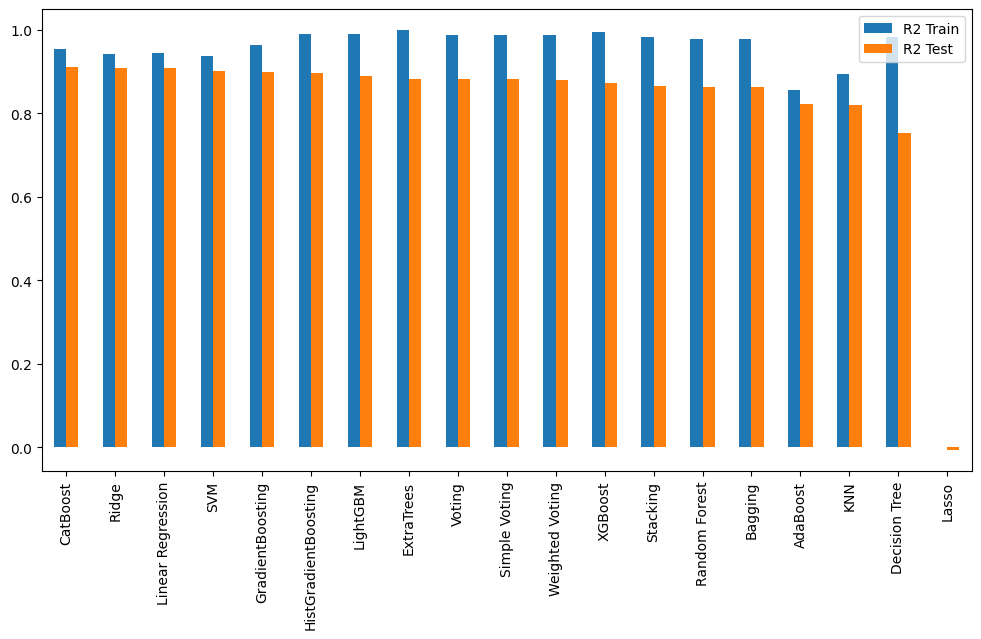

In [48]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

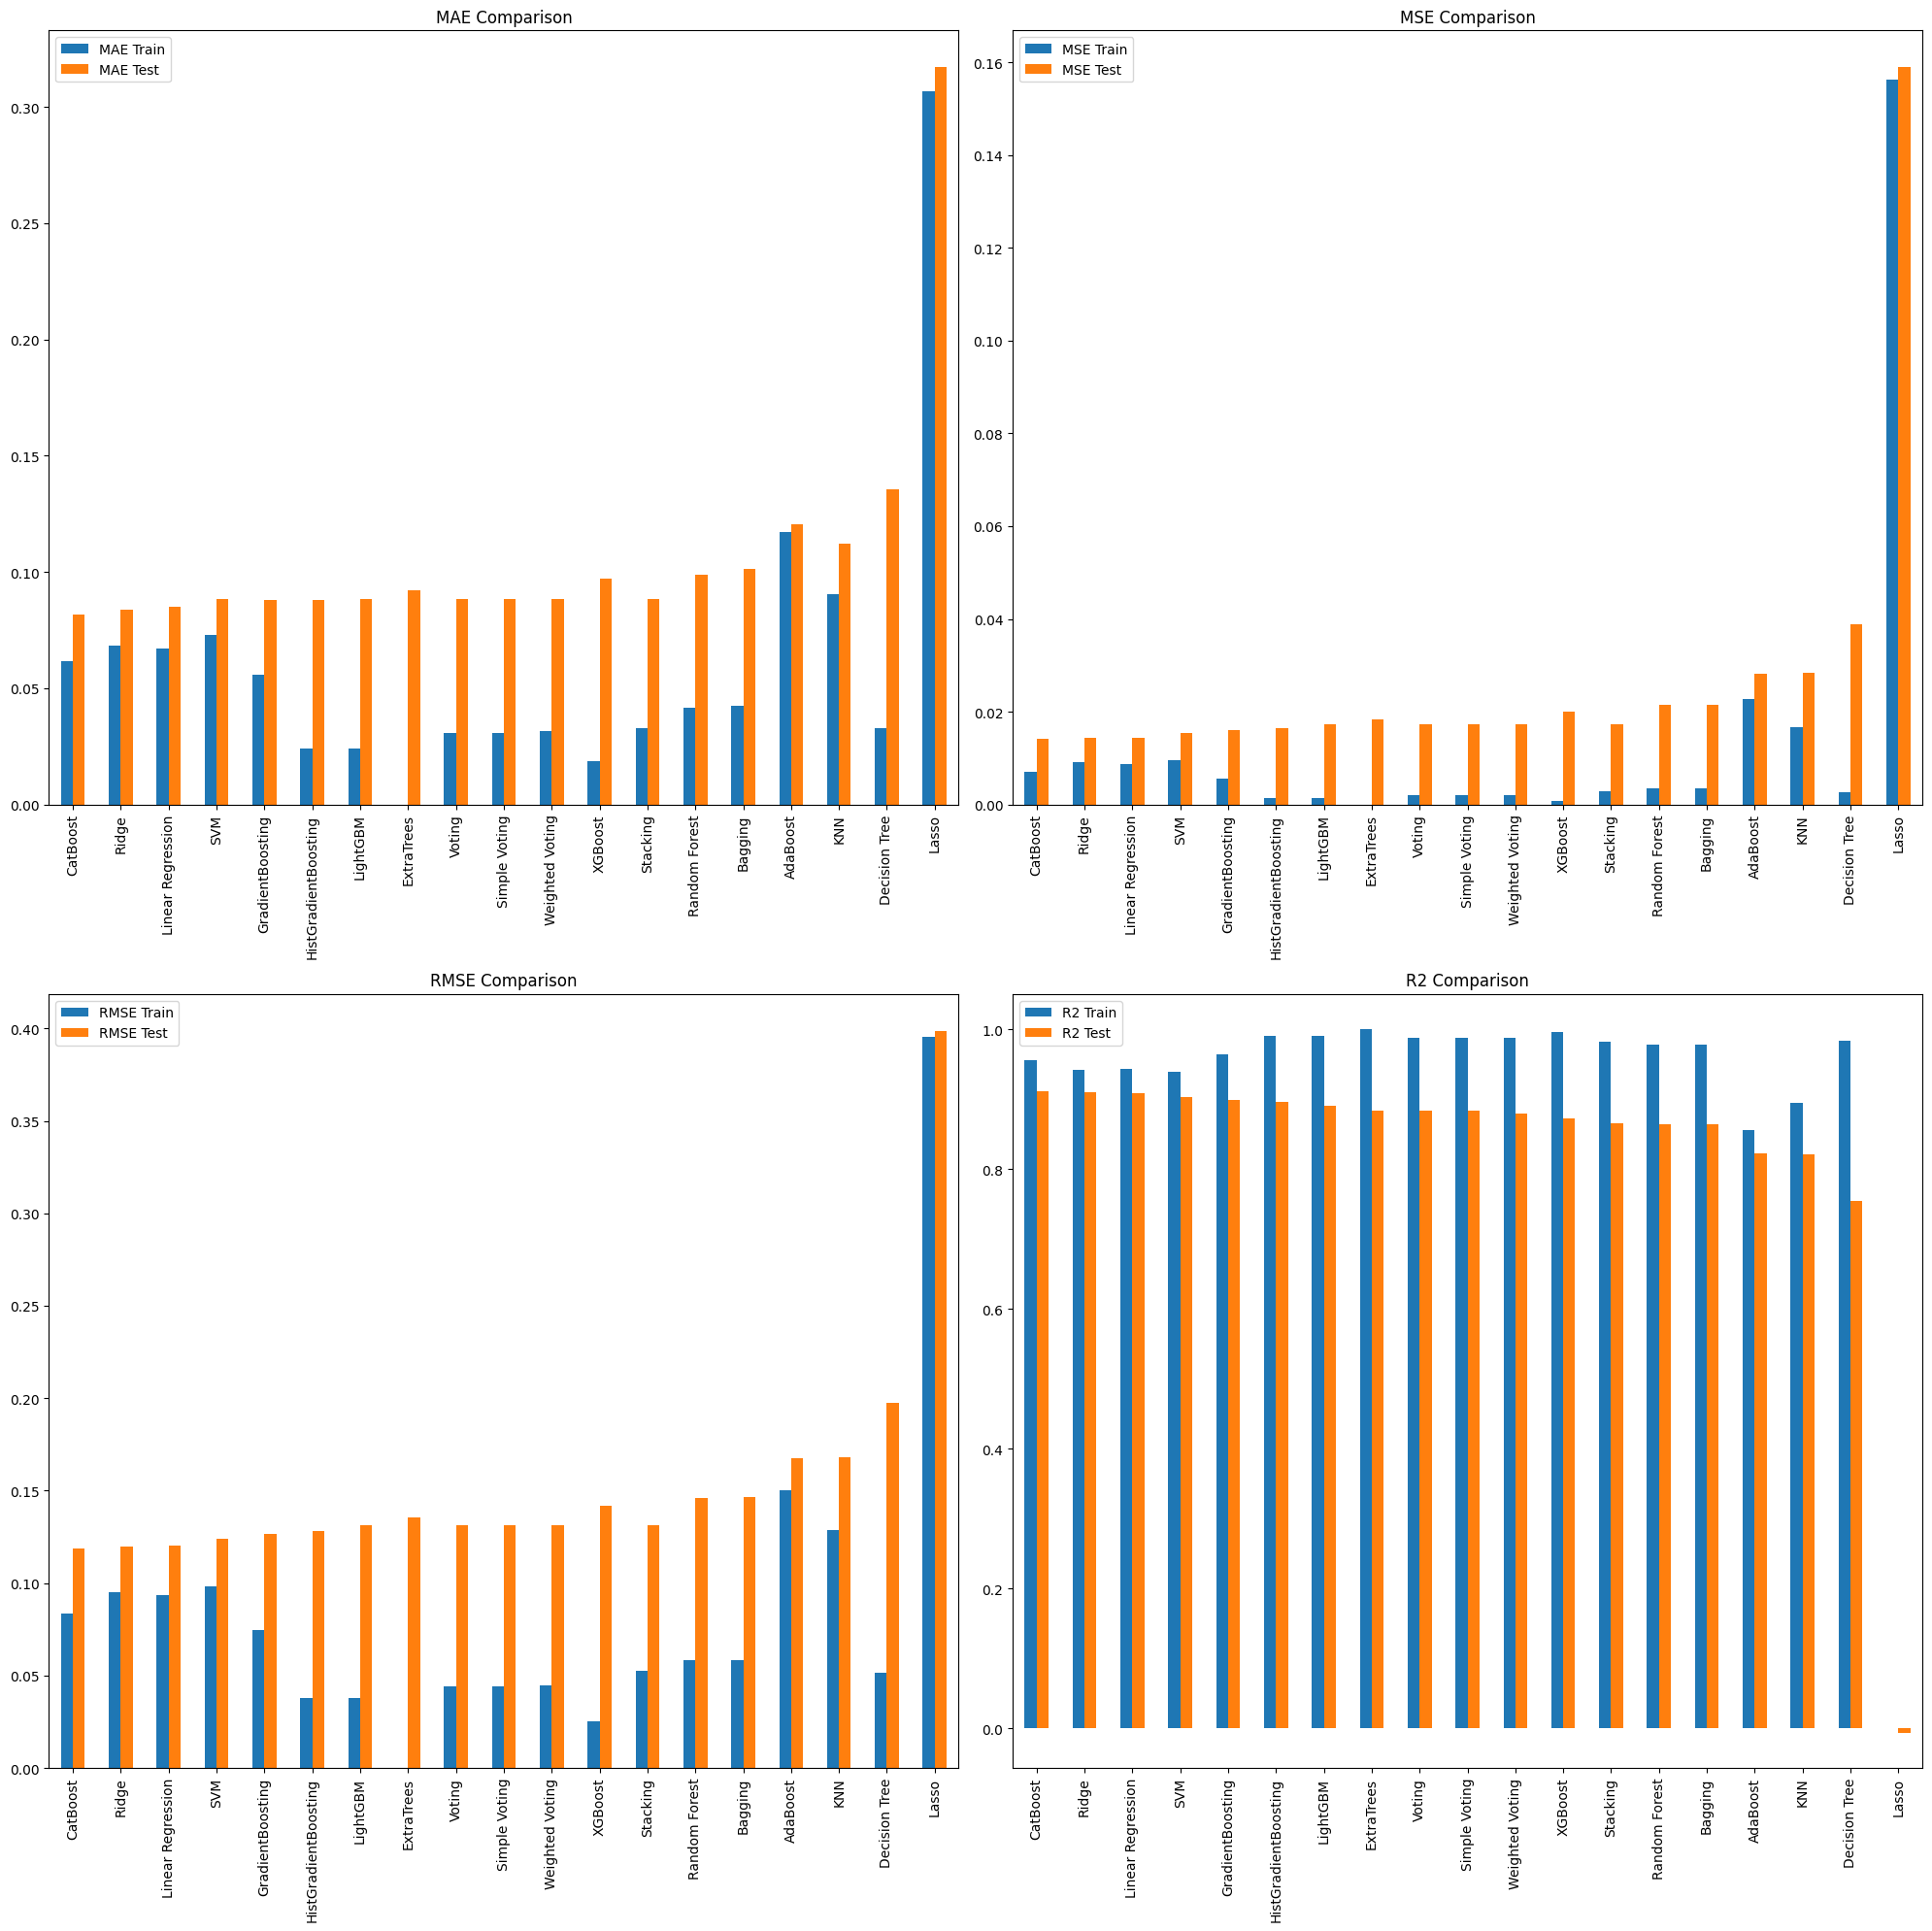

In [49]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

In [50]:
from sklearn.decomposition import PCA
pc=PCA(n_components=10,random_state=42)
X_train_PCA=pc.fit_transform(X_train)
X_test_PCA=pc.transform(X_test)

In [51]:
X_train_PCA.shape

(1164, 10)

In [52]:
import gradio as gr

raw_X = df_clean.drop(columns="SalePrice")
median_idx = (df_clean["SalePrice"] - df_clean["SalePrice"].median()).abs().idxmin()
typical_house = raw_X.loc[[median_idx]]


def prepare_row(row):

    row = row.copy()
    for col in quality_cols:
        row[col] = row[col].map(quality)
    row["CentralAir"] = row["CentralAir"].map({"N": 0, "Y": 1})
    row["MSSubClass"] = row["MSSubClass"].astype(str)

    for col in high_card:
        row[col] = row[col].map(target_means[col]).fillna(y_train.mean())

    # من غير drop_first (الصف واحد فكان هيمسح الأعمدة النصية)، و reindex بيرتب الأعمدة
    row = pd.get_dummies(row, columns=onehot_cols)
    row = row.reindex(columns=X.columns, fill_value=0).astype(float)

    row[skewed] = np.log1p(row[skewed])
    row[num_cols] = scaler.transform(row[num_cols])
    return row


def predict_price(overall_qual, gr_liv_area, total_bsmt_sf, garage_cars, year_built,
                  lot_area, full_bath, neighborhood, kitchen_qual, exter_qual):
    numbers = [overall_qual, gr_liv_area, total_bsmt_sf, year_built, lot_area]
    if any(v is None for v in numbers):
        return " "

    row = typical_house.copy()
    row["OverallQual"] = int(overall_qual)
    row["GrLivArea"] = gr_liv_area
    row["TotalBsmtSF"] = total_bsmt_sf
    row["GarageCars"] = int(garage_cars)
    row["YearBuilt"] = year_built
    row["LotArea"] = lot_area
    row["FullBath"] = int(full_bath)
    row["Neighborhood"] = neighborhood
    row["KitchenQual"] = kitchen_qual
    row["ExterQual"] = exter_qual

    price = np.expm1(best_model.predict(prepare_row(row)))[0]
    return f"Estimated Price: ${price:,.0f}"


demo = gr.Interface(
    fn=predict_price,
    inputs=[
        gr.Slider(1, 10, step=1, value=6, label="Overall Quality (1-10)"),
        gr.Number(label="Living Area (sq ft)", value=1500),
        gr.Number(label="Total Basement (sq ft)", value=1000),
        gr.Dropdown(["0", "1", "2", "3", "4"], label="Garage Cars", value="2"),
        gr.Number(label="Year Built", value=1990, precision=0),
        gr.Number(label="Lot Area (sq ft)", value=9000),
        gr.Dropdown(["0", "1", "2", "3"], label="Full Bathrooms", value="2"),
        gr.Dropdown(sorted(df_clean["Neighborhood"].unique()), label="Neighborhood", value="NAmes"),
        gr.Dropdown(["Ex", "Gd", "TA", "Fa"], label="Kitchen Quality", value="TA"),
        gr.Dropdown(["Ex", "Gd", "TA", "Fa"], label="Exterior Quality", value="TA"),
    ],
    outputs=gr.Textbox(label="Prediction Result"),
    title="House Price Prediction App",
    description="Enter the main house details to estimate its sale price. Other details are set to a typical house.",
)

demo.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0081b91238c9c21675.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
